# WORD2VEC-SKIPGRAM(Corpus, c, d, eta, T)

Implementation of the skip-gram algorithm with full softmax, following the pseudocode from class:

1. Build vocabulary V from the corpus
2. Initialize input embeddings E randomly
3. Initialize output weights W randomly
4. Generate training pairs (center, context) within window c
5. For epoch = 1 to T: shuffle pairs, forward pass, compute loss, backprop, update
6. Return E


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


### Step 1 — build vocabulary V from the corpus

In [2]:
def build_vocab(corpus):
    vocab = sorted({w for sentence in corpus for w in sentence})
    word2idx = {w: i for i, w in enumerate(vocab)}
    idx2word = {i: w for w, i in word2idx.items()}
    return word2idx, idx2word


### Step 4 — generate training pairs (center, context) within window c

In [3]:
def generate_pairs(corpus, word2idx, c):
    pairs = []
    for sentence in corpus:
        for i in range(len(sentence)):
            for j in range(max(0, i - c), min(len(sentence), i + c + 1)):
                if i != j:
                    pairs.append((word2idx[sentence[i]], word2idx[sentence[j]]))
    return pairs


Softmax, used in the forward pass.

In [4]:
def softmax(x):
    x = x - np.max(x)
    e = np.exp(x)
    return e / e.sum()


### Steps 2, 3, 5, 6 — init E and W, train for T epochs, return E

`d` is the embedding dimension, `eta` is the learning rate, `T` is the number of epochs.

In [5]:
def word2vec_skipgram(corpus, c=2, d=10, eta=0.05, T=300, seed=0):
    rng = np.random.default_rng(seed)
    word2idx, idx2word = build_vocab(corpus)
    V = len(word2idx)

    E = rng.normal(0, 0.1, size=(V, d))   # input embeddings
    W = rng.normal(0, 0.1, size=(d, V))   # output weights

    pairs = generate_pairs(corpus, word2idx, c)
    losses = []

    for epoch in range(T):
        rng.shuffle(pairs)
        epoch_loss = 0.0

        for center, context in pairs:
            # forward pass
            h = E[center]
            scores = h @ W
            probabilities = softmax(scores)

            # loss
            epoch_loss += -np.log(probabilities[context] + 1e-12)

            # backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = W @ error

            # update parameters
            W = W - eta * gradient_W
            E[center] = E[center] - eta * gradient_h

        losses.append(epoch_loss / len(pairs))

    return E, word2idx, idx2word, losses


### Try it on a small toy corpus

vocab size: 17
loss, first epoch: 2.828863275276583 | last epoch: 1.905641440367601


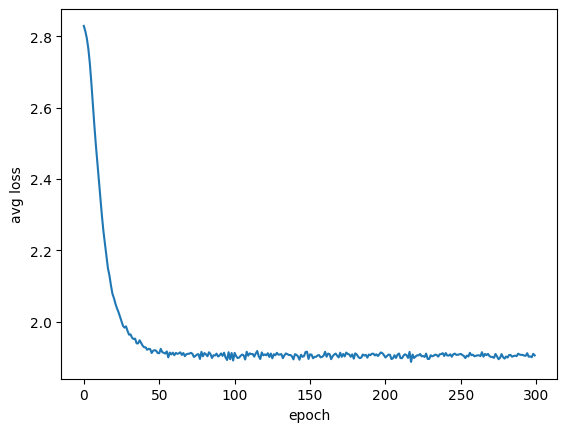

In [6]:
corpus = [
    "the king is a strong man".split(),
    "the queen is a wise woman".split(),
    "the prince is a young man".split(),
    "the princess is a young woman".split(),
    "man and woman are humans".split(),
    "king and queen rule the kingdom".split(),
]

E, word2idx, idx2word, losses = word2vec_skipgram(corpus, c=2, d=10, eta=0.05, T=300)
print("vocab size:", len(word2idx))
print("loss, first epoch:", losses[0], "| last epoch:", losses[-1])

plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("avg loss")
plt.show()


### Sanity check
If training worked, words that show up in similar contexts should end up close together in embedding space (cosine similarity).

In [7]:
def most_similar(word, topn=4):
    def cos(a, b):
        return a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)
    v = E[word2idx[word]]
    sims = [(idx2word[i], cos(v, E[i])) for i in range(len(word2idx)) if i != word2idx[word]]
    return sorted(sims, key=lambda x: -x[1])[:topn]

for w in ["king", "man", "woman"]:
    print(w, "->", most_similar(w))


king -> [('rule', np.float64(0.6990389043424582)), ('prince', np.float64(0.6360355228090461)), ('princess', np.float64(0.6321449360573169)), ('wise', np.float64(0.47168230491061974))]
man -> [('wise', np.float64(0.5701722090728907)), ('are', np.float64(0.49643781123264263)), ('woman', np.float64(0.341825928168038)), ('young', np.float64(0.29022080911356957))]
woman -> [('strong', np.float64(0.43895334106338446)), ('man', np.float64(0.341825928168038)), ('young', np.float64(0.22173012573398504)), ('is', np.float64(0.15296092132647604))]
